# Regression: Part 1
Regression is a <b>supervised learning</b> technique used to predict a <b>continuous numerical value</b> based on input features. The goal is to model the relationship between the features and the output.

### Types of Regression:
<b>1) Linear Regression:</b>
* Assumes a linear relationship between features and output, according to the following equation:

$$
y = Wx+b
$$


There are other models that are used to perform Regression. These are seen in the next parts.

## 1- Linear Regression
### 1.1 - Simple Linear Regression
Simple linear regression models a linear relationship between only <b>one feature</b> and the output

#### a - Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### b - Importing Dataset
This is a dataset regrouping information about a company, which collected data about the years of experience (column <b>'YearsExperience'</b>) of their employees, as well as their salaries (column <b>'Salary'</b>) .

For an employee, <b> that has a specific years of experience </b>, the company will want to know what would be <b>the appropriate Salary</b>. 

The company has hired you as a data scientist and Machine learning specialist to perform the previous task, based on <b>Simple Linear Regression algorithm.</b> 

In [2]:
# importing and displaying dataset 
data = pd.read_csv('../data/Salary_Data.csv')
data

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [4]:
# Creating Feature vector and output vector
x = data.iloc[:, :-1].values
y = data.iloc[:, -1].values
x

array([[ 1.1],
       [ 1.3],
       [ 1.5],
       [ 2. ],
       [ 2.2],
       [ 2.9],
       [ 3. ],
       [ 3.2],
       [ 3.2],
       [ 3.7],
       [ 3.9],
       [ 4. ],
       [ 4. ],
       [ 4.1],
       [ 4.5],
       [ 4.9],
       [ 5.1],
       [ 5.3],
       [ 5.9],
       [ 6. ],
       [ 6.8],
       [ 7.1],
       [ 7.9],
       [ 8.2],
       [ 8.7],
       [ 9. ],
       [ 9.5],
       [ 9.6],
       [10.3],
       [10.5]])

#### c - Splitting Data into Training and Test Sets
In Machine Learning, generally we divide our dataset into 2 separate sets: Training set and Test set.

* <b>Training set</b>: is a portion of data on which we are training our ML model using some ML algorithm.
* <b>Test set</b>: This is supposed to be a brand new data on which we test the performance of the ML model, by comparing the predicted values (from the model), with the actual ones.

In [5]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=1/3, random_state=0)

x_train

array([[ 2.9],
       [ 5.1],
       [ 3.2],
       [ 4.5],
       [ 8.2],
       [ 6.8],
       [ 1.3],
       [10.5],
       [ 3. ],
       [ 2.2],
       [ 5.9],
       [ 6. ],
       [ 3.7],
       [ 3.2],
       [ 9. ],
       [ 2. ],
       [ 1.1],
       [ 7.1],
       [ 4.9],
       [ 4. ]])

#### d - Training the Simple Linear Regression algorithm on Training Set

In [6]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9345.94]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.682e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[11.32]


#### e - Testing the Simple Linear Regression algorithm on Test Set

In [7]:
y_pred = model.predict(x_test)

In [8]:
y_pred

array([ 40835.10590871, 123079.39940819,  65134.55626083,  63265.36777221,
       115602.64545369, 108125.8914992 , 116537.23969801,  64199.96201652,
        76349.68719258, 100649.1375447 ])

#### f - Visualizing Training set results

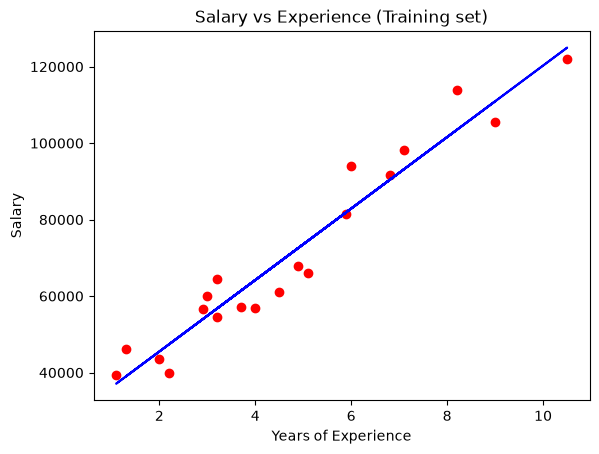

In [9]:
plt.scatter(x_train, y_train, color='red')
plt.plot(x_train, model.predict(x_train), color='blue')
plt.title('Salary vs Experience (Training set)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()

#### g- Visualizing Test set results

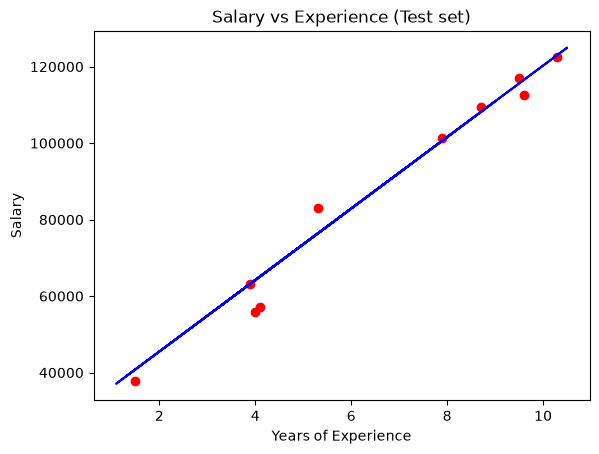

In [10]:
plt.scatter(x_test, y_test, color='red')
plt.plot(x_train, model.predict(x_train), color='blue')
plt.title('Salary vs Experience (Test set)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()

#### Question: What are W and b parameters of the model?

In [11]:
from sklearn.metrics import r2_score
print('W =', model.coef_[0])
print('b =', model.intercept_)
print('R2 on the test set =', r2_score(y_test, y_pred))

W = 9345.942443122372
b = 26816.192244031183
R2 on the test set = 0.9749154407708353


**Answer:** `W` is the slope (`model.coef_`), the salary gained per extra year of experience, and `b` is the intercept (`model.intercept_`), the predicted starting salary. Their values are printed above.